In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, roc_auc_score
)

%matplotlib inline

In [15]:
df = pd.read_csv("heart.csv")

print("Dataset Shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())
print("\nTarget counts (0 = No Disease, 1 = Disease):\n", df['target'].value_counts())

df.head()

Dataset Shape: (1025, 14)

Missing values:
 age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Target counts (0 = No Disease, 1 = Disease):
 target
1    526
0    499
Name: count, dtype: int64


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


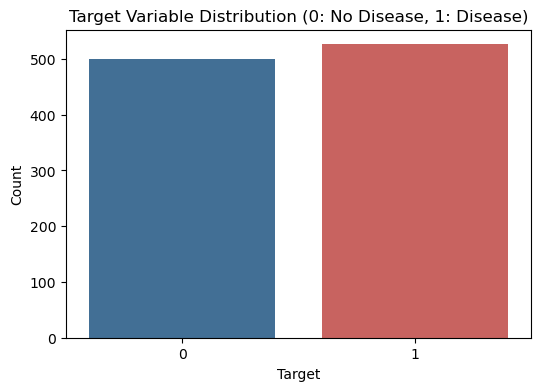

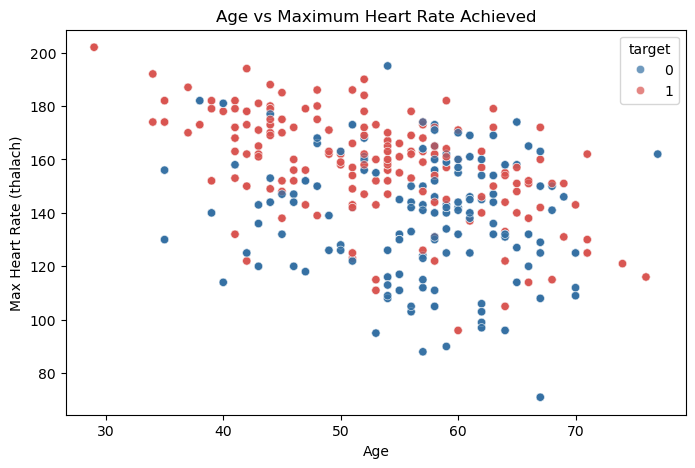

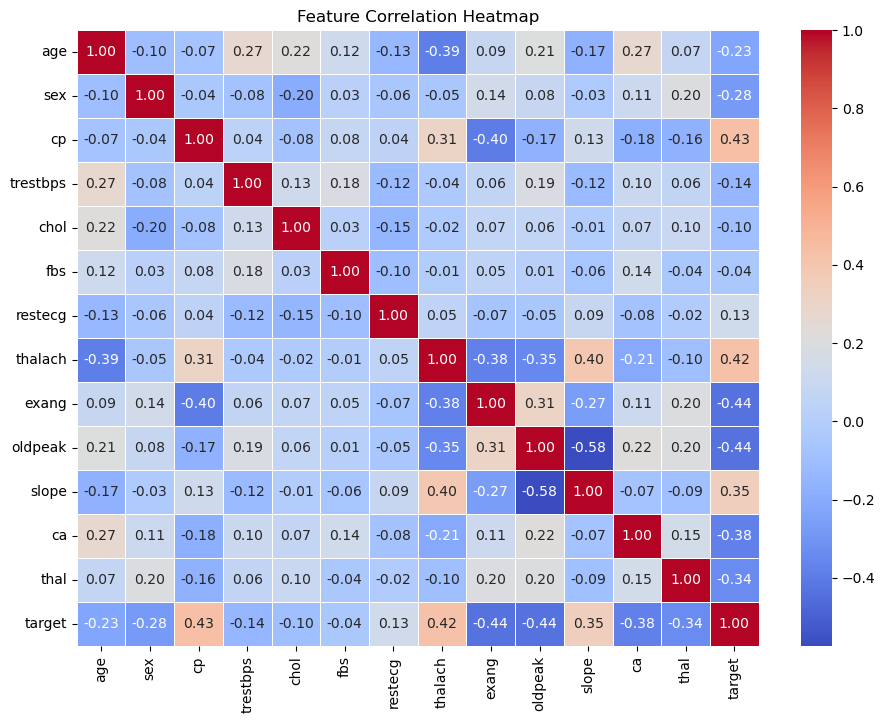

In [16]:
# 1. Target Class Balance
plt.figure(figsize=(6, 4))
sns.countplot(x='target', data=df, hue='target', palette=['#3470a3', '#d9534f'], legend=False)
plt.title('Target Variable Distribution (0: No Disease, 1: Disease)')
plt.xlabel('Target')
plt.ylabel('Count')
plt.show()

# 2. Age vs Max Heart Rate
plt.figure(figsize=(8, 5))
sns.scatterplot(x='age', y='thalach', hue='target', data=df, palette=['#3470a3', '#d9534f'], alpha=0.7)
plt.title('Age vs Maximum Heart Rate Achieved')
plt.xlabel('Age')
plt.ylabel('Max Heart Rate (thalach)')
plt.show()

# 3. Correlation Heatmap
plt.figure(figsize=(11, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Feature Correlation Heatmap')
plt.show()

In [17]:
# Features (X) and Target (y)
X = df.drop(columns=['target'])
y = df['target']

# 80/20 Train-Test Split with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Standardize/Normalize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training shape:", X_train_scaled.shape)
print("Testing shape :", X_test_scaled.shape)

Training shape: (820, 13)
Testing shape : (205, 13)


In [18]:
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

# Predict labels and probabilities
y_pred = model.predict(X_test_scaled)
y_pred_prob = model.predict_proba(X_test_scaled)[:, 1]

print("Model training complete.")

Model training complete.


In [19]:
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"F1 Score : {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_pred_prob):.4f}")

print("\n--- Detailed Classification Report ---")
print(classification_report(y_test, y_pred, target_names=['No Disease (0)', 'Disease (1)']))

Accuracy : 0.8098
Precision: 0.7619
Recall   : 0.9143
F1 Score : 0.8312
ROC-AUC  : 0.9298

--- Detailed Classification Report ---
                precision    recall  f1-score   support

No Disease (0)       0.89      0.70      0.78       100
   Disease (1)       0.76      0.91      0.83       105

      accuracy                           0.81       205
     macro avg       0.82      0.81      0.81       205
  weighted avg       0.82      0.81      0.81       205



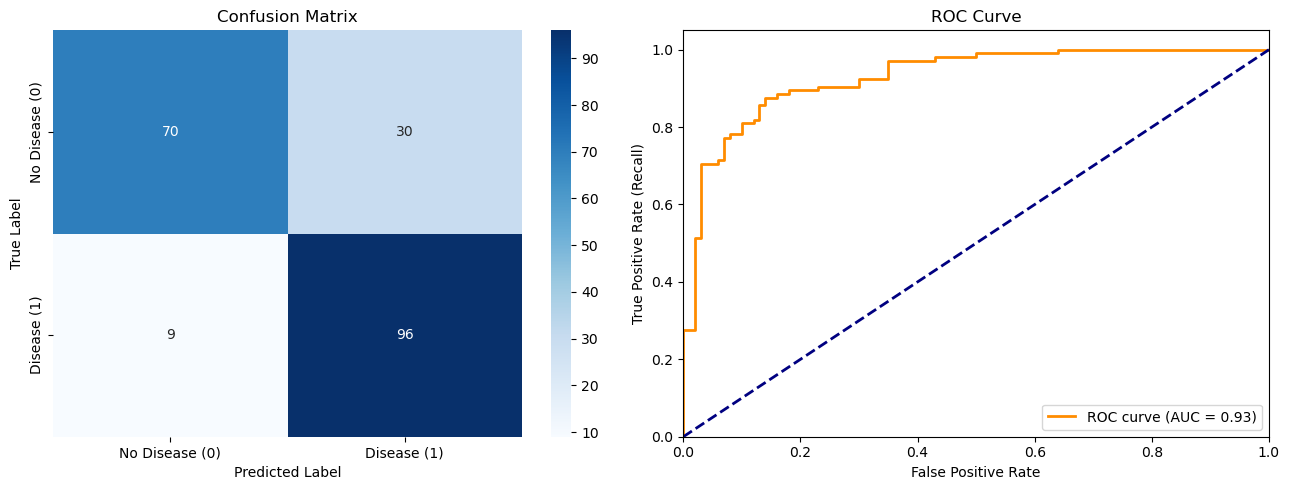

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['No Disease (0)', 'Disease (1)'],
            yticklabels=['No Disease (0)', 'Disease (1)'])
axes[0].set_title('Confusion Matrix')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# ROC Curve Plot
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
auc_val = roc_auc_score(y_test, y_pred_prob)
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc_val:.2f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate (Recall)')
axes[1].set_title('ROC Curve')
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()